# GD with Back tracking armijo Condition:

$$f(x^{k+1}) \le f(x^k) + c_1 \alpha^k \nabla f(x^k)^T d^k$$

[0]: Current alpha 0.016796159999999997, Current Height 43.47388115234829, Current Point -2.910991359999999
[1]: Current alpha 0.046655999999999996, Current Height -0.7637807357882089, Current Point 0.8309835741221545
[2]: Current alpha 0.216, Current Height -1.049053903478039, Current Point 1.196155937818389
[3]: Current alpha 0.1296, Current Height -1.0681284738628263, Current Point 1.1094727785581469
[4]: Current alpha 0.216, Current Height -1.0682273123754975, Current Point 1.1513992520486125
[5]: Current alpha 0.1296, Current Height -1.0701103141081802, Current Point 1.1258242928956632
[6]: Current alpha 0.1296, Current Height -1.0702252378914705, Current Point 1.1319291182733775
[7]: Current alpha 0.1296, Current Height -1.070229957301565, Current Point 1.1306819416960745
[8]: Current alpha 0.1296, Current Height -1.0702301717780567, Current Point 1.1309473737303466
[9]: Current alpha 0.1296, Current Height -1.0702301813290054, Current Point 1.13089134122935
[10]: Current alpha 0

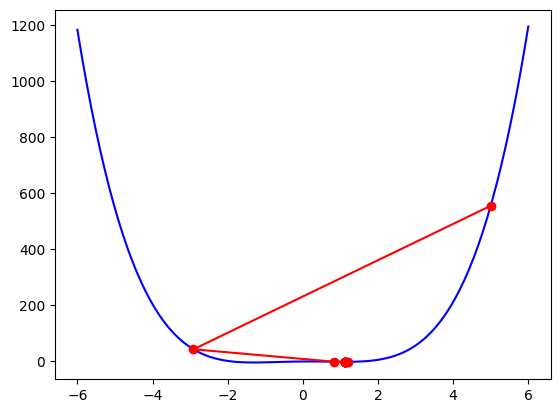

In [ ]:
#1D

import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return x**4 - 3*(x**2) + x

def grad_f(x):
    return 4*(x**3) - 6*x + 1

def hessian(x):
    return 12*(x**2) - 6

alpha = 1
current_point= 5
c = 1e-2
p = 0.6
max_iter=1000
k=0
tol = 1e-6
history_of_points = [current_point]

while np.linalg.norm(grad_f(current_point))> tol and max_iter>k:

    #now we try to get the direction
    direction = -grad_f(current_point)

    #we will make alpha 1 everytime so it get compatible to each new current points
    alpha = 1

    #now lets loop around to get the alpha first: so as you see the formula on top is the armijo condition we will revert it so we can find if alpha is sitting higher than the upper bound
    while f(current_point + (direction * alpha)) > f(current_point) + c * alpha * np.transpose(grad_f(current_point)) * direction:

        alpha = p * alpha

    #now we will update the position on the alpha which got passed by armijo upper bound:
    new_pos = current_point + (alpha * direction)

    #update
    current_point = new_pos

    print(f'[{k}]: Current alpha {alpha}, Current Height {f(current_point)}, Current Point {current_point}')

    k = k + 1

    #save in history_of_points:
    history_of_points.append(current_point)

#plot:
X = np.linspace(-6,6,100)
Y = f(X)
plt.plot(X,Y, color='Blue', label = 'f(x)')

x = history_of_points
y = [f(i) for i in history_of_points]
plt.plot(x,y, color='Red', marker='o', label='Decent')
